# CUSTOMER SEGMENTATION

## DATASET OVERVIEW

https://www.kaggle.com/datasets/vishakhdapat/customer-segmentation-clustering

## LIBRARIES AND DATA IMPORT

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests

In [4]:
import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()
root.attributes('-topmost', True)   # porta la finestra in primo piano
file_path = filedialog.askopenfilename(
    title='Select the customer segmentation CSV',
    filetypes=[('CSV files', '*.csv')]
)
root.destroy()

customer_df = pd.read_csv(file_path)
customer_df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## DATA CLEANING AND EXPLORATORY DATA ANALYSIS (EDA)

In [5]:
customer_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

NOTE: dt_customer rappresents the date when the customer was first enrolled or became a part of the company's database. The data type has to be converted.

Let's check for null values

In [6]:
customer_df.isna().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

There's a few missing income data, but not many. Overall the dataset is quite complete. If we want to use this feature to identify clusters with K-Means, we will need to either impute the missing values ​​or remove the rows where the 'Income' value is null. Scikit-learn’s K-Means does not accept missing values ​​and will raise a ValueError if there are any NaNs in X_scaled.

In [7]:
customer_df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [8]:
customer_df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

NOTE: Let's keep an eye on the "Absurd" and "YOLO" value. Should they be treated as missing or non-classified?

### DATA CLEANING

The following steps involved data cleaning and the creation of new variables.

converting date type.

In [9]:
df_cust = customer_df.copy()
df_cust['Dt_Customer'] = pd.to_datetime(df_cust['Dt_Customer'], dayfirst=True)
df_cust.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   str           
 3   Marital_Status       2240 non-null   str           
 4   Income               2216 non-null   float64       
 5   Kidhome              2240 non-null   int64         
 6   Teenhome             2240 non-null   int64         
 7   Dt_Customer          2240 non-null   datetime64[us]
 8   Recency              2240 non-null   int64         
 9   MntWines             2240 non-null   int64         
 10  MntFruits            2240 non-null   int64         
 11  MntMeatProducts      2240 non-null   int64         
 12  MntFishProducts      2240 non-null   int64         
 13  MntSweetProducts     2240 non-null   int64  

we'll have to drop NaN values to apply K-Means or need to replace these values ​​with the median or the mean.

In [10]:
income_median = df_cust['Income'].median() #let's replace them eith the median
df_cust['Income'] = df_cust['Income'].fillna(income_median)

calculating customer age

In [11]:
df_cust['Age']= 2026 - df_cust['Year_Birth']

let's create Age Group

In [12]:
bins = [30,40,50,60,70,80]

In [13]:
labels = ['18-39','40-49','50-59','60-69','70+'] #there are only 2 people under 30, so we merged the age groups

In [14]:
df_cust['Age_Group'] = pd.cut(df_cust['Age'], bins=bins, labels=labels)

In [15]:
df_cust['Age_Group'].value_counts()

Age_Group
50-59    685
40-49    506
60-69    492
70+      341
18-39    187
Name: count, dtype: int64

Calculating total children number

In [16]:
df_cust['Total_Children']= df_cust['Kidhome'] + df_cust['Teenhome']

Calculating total spending

In [17]:
df_cust.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'Age_Group', 'Total_Children'],
      dtype='str')

In [18]:
spending_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
       'MntSweetProducts', 'MntGoldProds']
df_cust['Total_Spending'] = df_cust[spending_cols].sum(axis=1)

Calculating years as customer

In [19]:
df_cust['Time_as_Cust'] = (pd.Timestamp("today")) - df_cust['Dt_Customer']

In [20]:
df_cust['Time_as_Cust']

0      5155 days 10:24:47.635991
1      4605 days 10:24:47.635991
2      4804 days 10:24:47.635991
3      4631 days 10:24:47.635991
4      4653 days 10:24:47.635991
                  ...           
2235   4873 days 10:24:47.635991
2236   4511 days 10:24:47.635991
2237   4647 days 10:24:47.635991
2238   4648 days 10:24:47.635991
2239   5114 days 10:24:47.635991
Name: Time_as_Cust, Length: 2240, dtype: timedelta64[us]

Let's handle the outliers for marital status (Alone, YOLO, and Absurd).

In [21]:
df_cust[df_cust['Marital_Status'].isin(['Absurd','YOLO'])][['Income','Total_Spending','Age']]

,Income,Total_Spending,Age
2093,79244.0,1216,33
2134,65487.0,1169,69
2177,48432.0,424,53
2202,48432.0,424,53


In [22]:
df_cust['Marital_Status'] = df_cust['Marital_Status'].replace({'Alone': 'Single'})
df_cust['Marital_Status'] = df_cust['Marital_Status'].replace({'YOLO': np.nan, 'Absurd': np.nan})

### DATA EXPLORATION AND DATA VIZ

Let us visualize the distribution of some of the numerical features to gain customer insight.

In [23]:
cols_to_viz = [ 'Age','Income', 'Total_Spending']

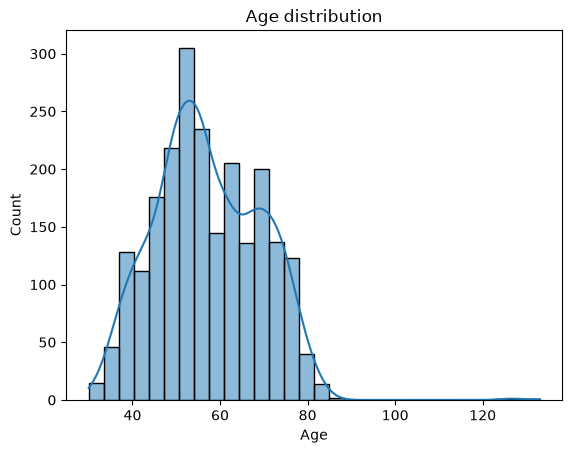

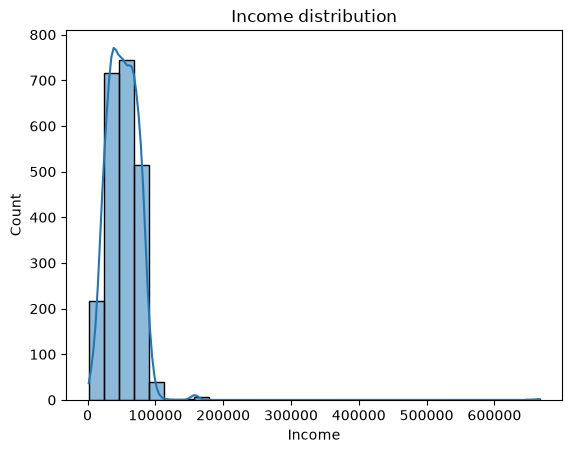

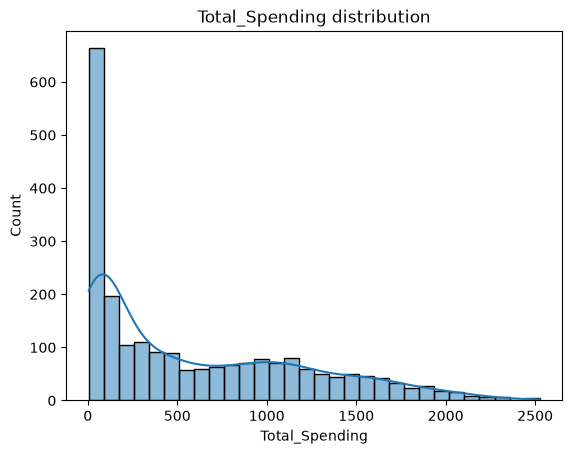

In [24]:
for i in cols_to_viz:
  sns.histplot(df_cust[i], bins= 30, kde=True)
  plt.title(f'{i} distribution')
  plt.show()

Overall, at first glance, we observe a customer base that is predominantly middle-aged, with income levels in the average to low-average range by American standards. The average spending is around $600 (presumably monthly); however, the median figures are much lower. This is evident from the histogram, which displays a long right tail.

This indicates that half of consumers spend less than $100 – 200, and the highest spending figures are driven by a few outliers.

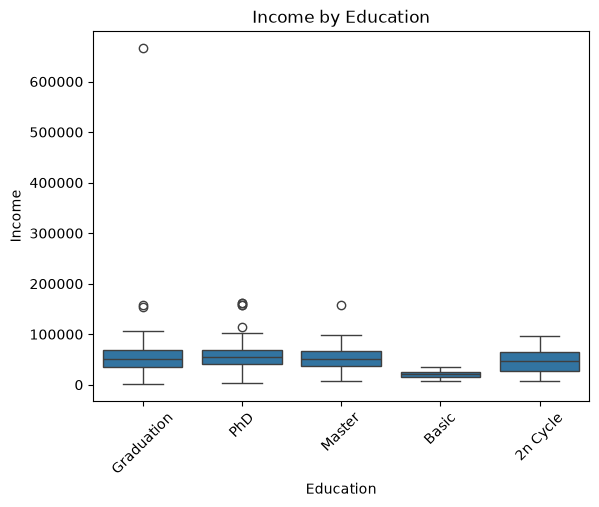

In [25]:
sns.boxplot(x="Education", y="Income", data= df_cust)
plt.xticks(rotation=45)
plt.title('Income by Education')
plt.show()

In [31]:
df_cust.groupby('Education')['Income'].agg(['mean', 'median', 'std']).sort_values(by='mean', ascending=False)

,mean,median,std
Education,,,
PhD,56096.303498,55005.0,20512.097287
Master,52896.777027,51044.5,20021.539473
Graduation,52707.305679,51651.0,28039.531293
2n Cycle,47688.583744,46891.0,21958.898270
Basic,20306.259259,20744.0,6235.066773


The data shown are in line with expectations. Income increases as the level of education rises. However, the most significant gap between groups occurs between the basic level of education and all higher levels.

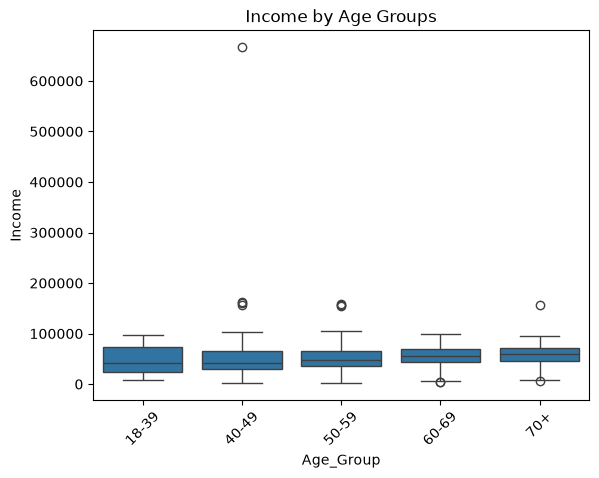

In [ ]:
sns.boxplot(x="Age_Group", y="Income", data= df_cust)
plt.xticks(rotation=45)
plt.title('Income by Age Groups')
plt.show()

In [30]:
df_cust.groupby('Age_Group')['Income'].agg(['mean', 'median', 'std']).sort_values(by='mean', ascending=False)

,mean,median,std
Age_Group,,,
70+,58130.807918,59111.0,18296.033161
60-69,55914.604675,56056.5,18624.058907
50-59,50488.540876,48240.0,20541.910661
40-49,48083.863636,41976.5,35980.366515
18-39,47942.652406,41411.0,26287.073838


Average income increases with age, but the difference between groups is small compared with the variability within each group (looking from the std values). Age doesn't seem to be a good predictor of income. The higher standard deviation in the 40-49 group is likely driven by an extreme outlier.
The 18–39 and 40–49 age groups have similar mean and median values. The younger groups are more heterogeneous. The outlier in the 40–49 group does not have a major impact on the mean, though it does have some effect. The groups aged 50 and over are similar in terms of standard deviation and exhibit more symmetrical income distributions (with the mean close to the median). Significant income growth occurs after the age of 50.

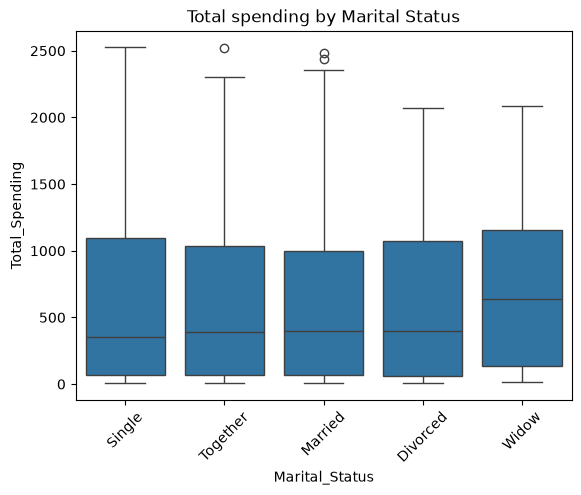

In [ ]:
sns.boxplot(x="Marital_Status", y="Total_Spending", data= df_cust)
plt.xticks(rotation=45)
plt.title('Total spending by Marital Status')
plt.show()

In [32]:
df_cust.groupby('Marital_Status')['Income'].agg(['mean', 'median', 'std']).sort_values(by='mean', ascending=False)

,mean,median,std
Marital_Status,,,
Widow,56415.318182,56551.0,16736.904128
Together,53223.037069,51381.5,33440.727270
Divorced,52834.228448,52683.0,21239.759765
Married,51722.196181,51521.0,21362.260861
Single,50957.785714,49166.0,21980.335945


Marital status says little about an individual client’s income, and even less about their age. The groups tend to overlap in terms of income level.

### CORRELATION

Let's look at the correlation between some of the numerical values

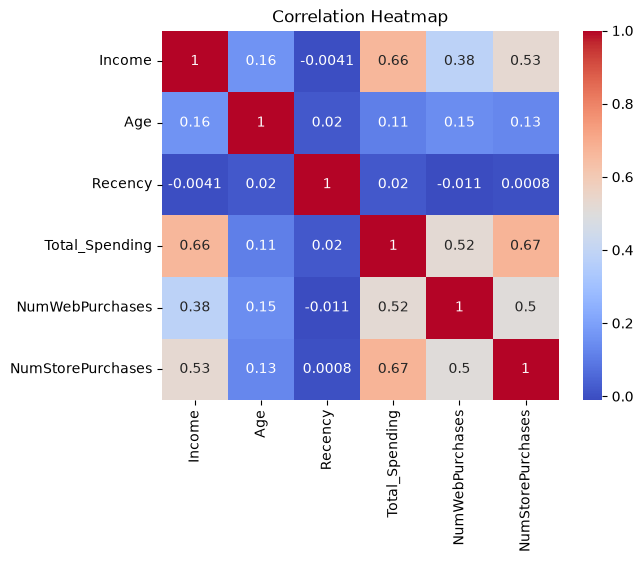

In [ ]:
corr_cols = df_cust[['Income','Age','Recency','Total_Spending','NumWebPurchases','NumStorePurchases']].corr()
sns.heatmap(corr_cols, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

We observe a moderate-to-high positive correlation between income level and total spending, as well as between the level of total spending and the volume of online and in-store purchases. These values are perfectly normal and expected.

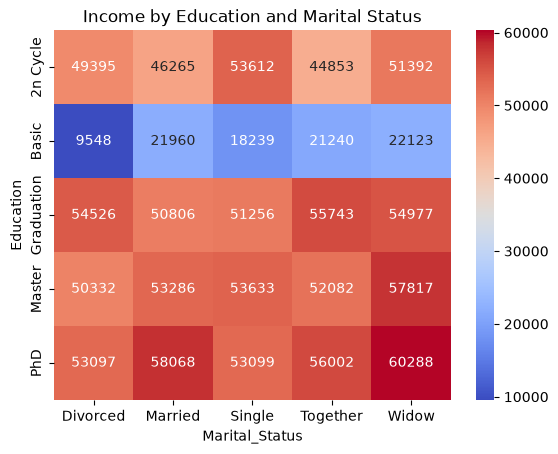

In [ ]:
pivot_income = df_cust.pivot_table(index='Education', columns='Marital_Status', values='Income', aggfunc='mean')
sns.heatmap(pivot_income, annot=True, fmt='.0f', cmap='coolwarm')
plt.title('Income by Education and Marital Status')
plt.show()

Education is the main driver of average income: the 'Basic' group stands out with much lower values than all other education levels. Outside 'Basic', differences across marital statuses within the same education level are small (but present) relative to within-group variability.

In [ ]:
group_edu_spending = df_cust.groupby('Education')['Total_Spending'].mean().sort_values(ascending=False)
group_edu_spending

Education
PhD           672.409465
Graduation    619.898846
Master        611.781081
2n Cycle      496.527094
Basic          81.796296
Name: Total_Spending, dtype: float64

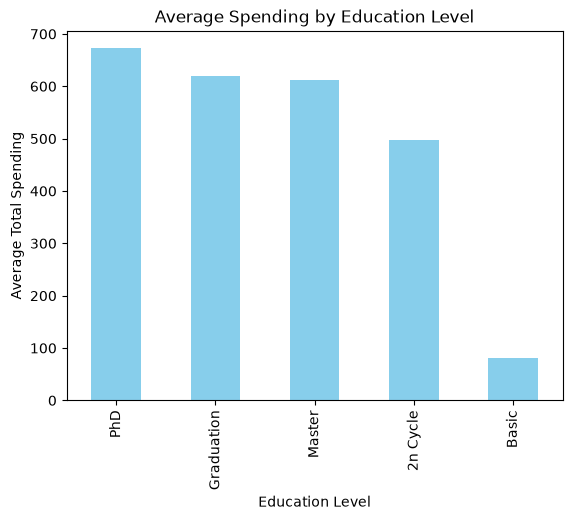

In [ ]:
group_edu_spending.plot(kind="bar", color = "skyblue")
plt.title('Average Spending by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Average Total Spending')
plt.show()

Out of curiosity, let's observe the acceptance rate of the previous marketing campaigns (mkt campaigns 1 to 5) by groups (marital status, maybe age bracket) and the acceptance rate of the last campaign ("Response")

In [ ]:
df_cust.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Age', 'Age_Group', 'Total_Children', 'Total_Spending', 'Time_as_Cust'],
      dtype='str')

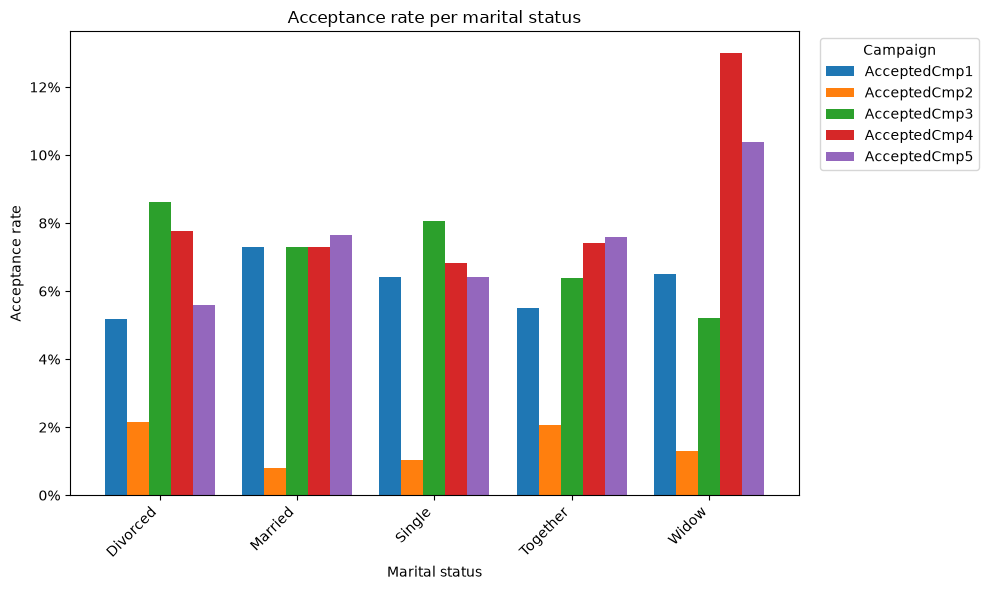

In [ ]:
campaigns = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3',
            'AcceptedCmp4', 'AcceptedCmp5']

# Acceptace rate for each marital status
rate = df_cust.groupby('Marital_Status')[campaigns].mean()

# Grouped bar chart x = marital status, each campaign is represented by a different bar
ax = rate.plot(kind='bar', figsize=(10, 6), width=0.8)

ax.set_ylabel('Acceptance rate')
ax.set_xlabel('Marital status')
ax.set_title('Acceptance rate per marital status')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(title='Campaign', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Let's create a dummy that indicates whether the customer responded to at least one of the previous 5 mkt campaigns.
This variable is different than "Response", which indicates the response to a 6th and last campaign separated from the previous 5.

In [ ]:
df_cust['Accepted_Any'] = df_cust[['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']].any(axis=1).astype(int)

In [ ]:
group_marital_campaign = df_cust.groupby('Marital_Status')['Accepted_Any'].mean().sort_values(ascending=False)
group_marital_campaign

Marital_Status
Widow       0.246753
Married     0.210648
Single      0.204969
Together    0.200000
Divorced    0.198276
Name: Accepted_Any, dtype: float64

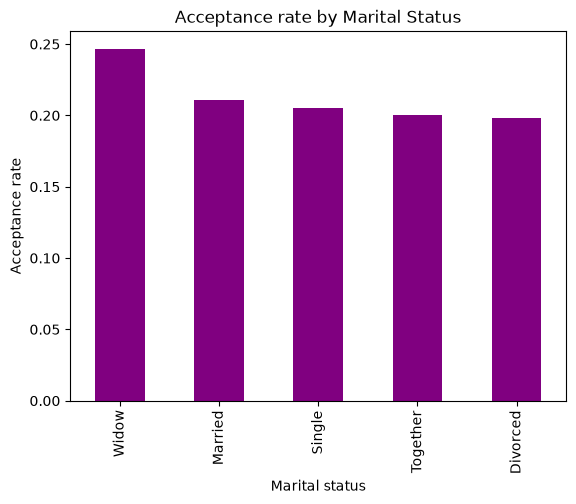

In [ ]:
group_marital_campaign.plot(kind="bar", color = "purple")
plt.title('Acceptance rate by Marital Status')
plt.xlabel('Marital status')
plt.ylabel('Acceptance rate')
plt.show()

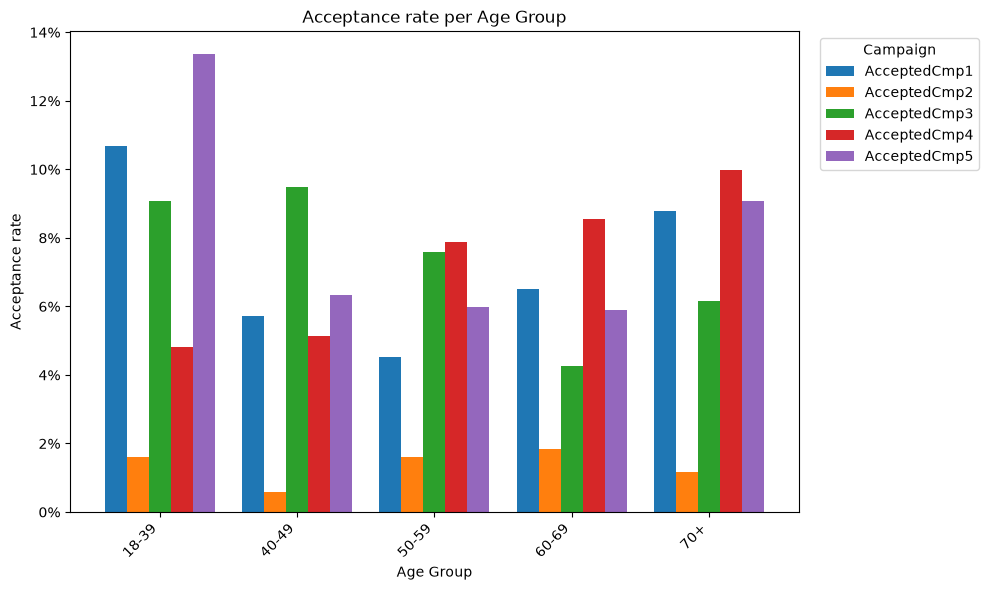

In [ ]:
# Acceptace rate for each age group
rate = df_cust.groupby('Age_Group')[campaigns].mean()

# Grouped bar chart x = age group, each campaign is represented by a different bar
ax = rate.plot(kind='bar', figsize=(10, 6), width=0.8)

ax.set_ylabel('Acceptance rate')
ax.set_xlabel('Age Group')
ax.set_title('Acceptance rate per Age Group')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend(title='Campaign', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
group_agegrp_campaign = df_cust.groupby('Age_Group')['Accepted_Any'].mean().sort_values(ascending=False)
group_agegrp_campaign

Age_Group
70+      0.246334
18-39    0.229947
60-69    0.201220
50-59    0.191241
40-49    0.185771
Name: Accepted_Any, dtype: float64

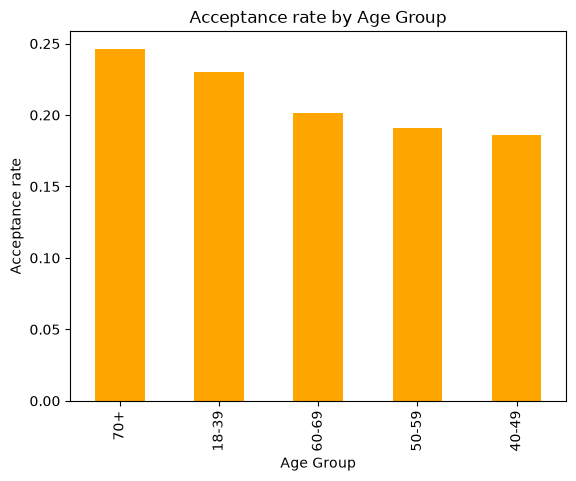

In [ ]:
group_agegrp_campaign.plot(kind="bar", color = "orange")
plt.title('Acceptance rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Acceptance rate')
plt.show()

Let's look a the Response to the 6th and last campaign (variable = "Response"). We'll test whether there is a statistically significant difference between age groups in terms of response rate.

Let's make the same test for "Education" and "Marital_Status"

In [ ]:
def chi2_test(data, var, target='Response'):

    tab = pd.crosstab(data[var], data[target])
    chi2, p, dof, _ = chi2_contingency(tab)
    n = tab.values.sum()
    v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    return {
        'variable': var,
        'n': n,
        'chi2': round(chi2, 2),
        'dof': dof,
        'p_value': round(p, 5),
        'cramers_v': round(v, 3)
    }

In [ ]:
# Deployment
variables = ['Age_Group', 'Education', 'Marital_Status']
results = pd.DataFrame([chi2_test(df_cust, v) for v in variables])
results

,variable,n,chi2,dof,p_value,cramers_v
0,Age_Group,2211,3.09,4,0.54251,0.037
1,Education,2240,23.08,4,0.00012,0.101
2,Marital_Status,2236,50.23,4,0.00000,0.150


Based on the p-value, we can conclude that there is no statistically significant difference in response rates to the latest campaign across the age groups. In the case of Marital Status and Education, the test shows that the response differs across groups in a statistically significant manner that cannot be attributed to chance.
Looking at the value of Cramer's V, we can conclude that an association exists, but it appears to be a weak one.

We will not investigate this point further, as it does not constitute the objective of the customer segmentation exercise.

## USING K-MEANS TO SEGMENT CUSTOMERS

We are going to select a few variables from the existing dataset that describe consumer characteristics.

In [62]:
features = ['Age','Income', 'Total_Spending','NumStorePurchases','NumWebPurchases','NumWebVisitsMonth','Recency']

In [63]:
X = df_cust[features].copy()

In [64]:
X

,Age,Income,Total_Spending,NumStorePurchases,NumWebPurchases,NumWebVisitsMonth,Recency
0,69,58138.0,1617,4,8,7,58
1,72,46344.0,27,2,1,5,38
2,61,71613.0,776,10,8,4,26
3,42,26646.0,53,4,2,6,26
4,45,58293.0,422,6,5,5,94
...,...,...,...,...,...,...,...
2235,59,61223.0,1341,4,9,5,46
2236,80,64014.0,444,5,8,7,56
2237,45,56981.0,1241,13,2,6,91
2238,70,69245.0,843,10,6,3,8


Let's scale our variables since they cover very different value ranges.

In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [66]:
X_scaled = scaler.fit_transform(X)

To apply K-Means, we need to know the value of K (clusters). To determine the optimal value, we use the elbow method.

In [67]:
from sklearn.cluster import KMeans

In [68]:
wcss = [] #Within-Cluster Sum of Squares

In [69]:
for i in range(2,10):
  kmeans = KMeans(n_clusters=i,random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  wcss.append(kmeans.inertia_)

In [70]:
wcss

[10368.63176028018,
 9150.71159481781,
 8290.172353320704,
 7694.74304030134,
 7212.500813093614,
 6823.565359268478,
 6260.191020620887,
 5988.430353174986]

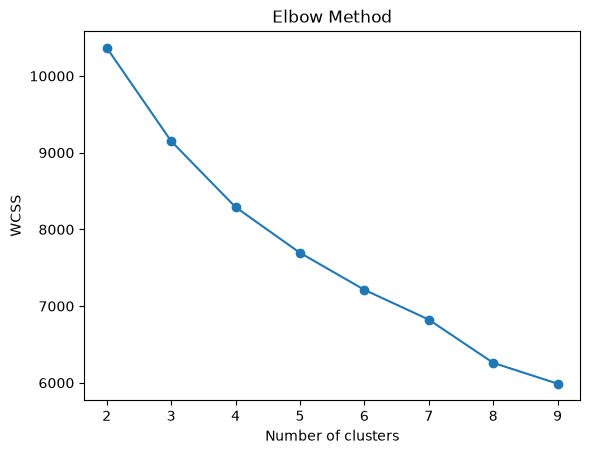

In [71]:
plt.plot(range(2,10),wcss, marker= "o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

Both k=4 and k=6 show an "elbow" bend. Let's choose k=6.

In [72]:
kmeans = KMeans(n_clusters=6,random_state=42, n_init=10)
df_cust['Cluster'] = kmeans.fit_predict(X_scaled) #let's add the cluster column

Now we should look at the characteristics of each cluster to try to interpret them.

In [73]:
cluster_summary = df_cust.groupby('Cluster')[features].mean()
cluster_summary

,Age,Income,Total_Spending,NumStorePurchases,NumWebPurchases,NumWebVisitsMonth,Recency
Cluster,,,,,,,
0,49.973214,33882.034598,121.647321,3.352679,2.234375,6.542411,22.895089
1,70.328313,73424.200301,1202.117470,8.569277,4.659639,2.753012,51.331325
2,69.209375,43420.267188,173.537500,4.003125,2.596875,5.418750,53.909375
3,59.918854,59804.337709,893.594272,7.854415,8.026253,6.398568,46.276850
4,50.120823,32390.011568,110.758355,3.143959,2.280206,7.115681,75.380463
5,47.072289,78026.691265,1296.246988,8.518072,4.581325,2.653614,50.427711


In [74]:
df_cust['Cluster'].value_counts()

Cluster
0    448
3    419
4    389
1    332
5    332
2    320
Name: count, dtype: int64

- CLUSTER 0: Low average income, low average spending, few purchases (store and web), high web visits, recency ~23 days (the lowest of all clusters).
Low value but recently active. Same profile as cluster 4, but more active. We could on engagement and on increasing basket size as a strategy.

- CLUSTER 1: Old segment , high average income , very high average spending , high store purchases , moderate web purchases, few web visits , recency ~51 days.
Top spenders with a traditional, store-oriented, purpose-driven behavior. Haven't purchased in about seven weeks. Worth contacting to keep the relation alive and monitoring the effects of the strategy.

- CLUSTER 2: Old, mid-low average income , low  average spending , few purchases (web and store), medium web visits , recency ~54 days.
Mature, low-to-mid spenders. Slightly more in-store than online. Lower priority.

- CLUSTER 3: Middle-aged, higher average income , high average spending , high store and web purchases , high web visits , recency ~46 days.
High value, omnichannel and digital. Only segment where web purchases match store purchases. Recency is medium, worth monitoring.

- CLUSTER 4: Low average income , low average spending , few purchases, highest web visits  highest recency (~75 days).
Low value, at risk of churn. Many visits but few purchases: possible price sensitivity (hypothesis). Strategy: Reactivation and online promotions.

- CLUSTER 5: Youngest segment , highest average income and spending , high store purchases , few web visits, recency ~50 days.
Top spenders with a traditional, store-oriented behavior, similar to cluster 1 but about 23 years younger. Haven't purchased in about seven weeks. Worth a proactive contact and a strategy tailored to a younger high-value customer.

Let's visualize the clusters with a scatterplot. We need a PCA to reduce the multiple features into 2. PCA allows data to be displayed on two axes (PCA1 and PCA2), chosen to preserve as much of the original variance as possible.

In [75]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)
df_cust['PCA1'], df_cust['PCA2'] = pca_data[:, 0], pca_data[:,1]

In [76]:
print(pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum())

[0.43056751 0.14475085] 0.5753183578612299


In [77]:
loadings = pd.DataFrame(pca.components_.T, index=features, columns=['PCA1', 'PCA2'])
print(loadings.round(2))

                   PCA1  PCA2
Age                0.14  0.18
Income             0.47  0.05
Total_Spending     0.51 -0.03
NumStorePurchases  0.47 -0.08
NumWebPurchases    0.36 -0.30
NumWebVisitsMonth -0.38 -0.28
Recency            0.01  0.89


In [78]:
for comp in ['PCA1', 'PCA2']:
    print(f'\n{comp}')
    print(loadings[comp].sort_values(key=abs, ascending=False).round(2))


PCA1
Total_Spending       0.51
Income               0.47
NumStorePurchases    0.47
NumWebVisitsMonth   -0.38
NumWebPurchases      0.36
Age                  0.14
Recency              0.01
Name: PCA1, dtype: float64

PCA2
Recency              0.89
NumWebPurchases     -0.30
NumWebVisitsMonth   -0.28
Age                  0.18
NumStorePurchases   -0.08
Income               0.05
Total_Spending      -0.03
Name: PCA2, dtype: float64


We consider loading levels above 0.30 to interpret the components.

The first principal component (43% of the variance) reflects customer value: it loads positively on total spending, income, and purchases, and negatively on site visits. The second (14%) is dominated by recency (loading 0.89) and indicates the time elapsed since the last purchase. The graph can therefore be interpreted as a customer value × recency map.

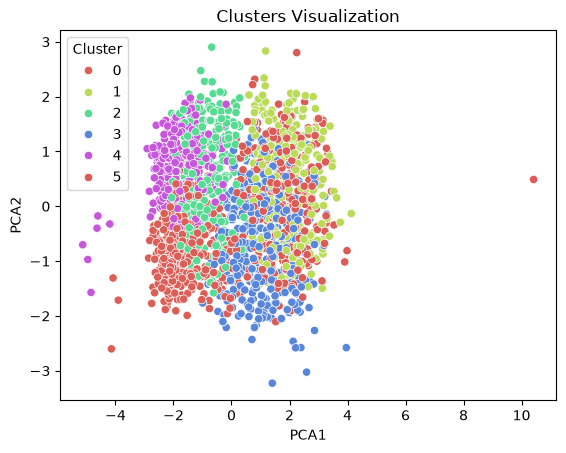

In [79]:
sns.scatterplot(x='PCA1', y='PCA2', hue='Cluster', palette='hls', data=df_cust)
plt.title('Clusters Visualization')
plt.show()

Let's save the trained model. We will use it to build a streamlit interface, used to make predictions on new customer data.

In [80]:
import joblib

joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler_model.pkl')

['scaler_model.pkl']